# 第 7 讲：机器学习基础与朴素贝叶斯
## Interactive PBL Worksheet + Reproducible Lab（教师/审阅者已填写稿）

> **用途边界**：这份 Notebook 只用于机器学习教学。它使用的是医学专家按规则构造出来的公开教学数据，不能拿去支持临床诊断、患者照护、模型部署或任何因果结论。

> **分发提醒**：本版本已填好全部示范答案，供课程设计审阅使用，**不要直接当作学生的空白 worksheet 发出去**。发给学生的是同目录下的 `pbl-machine-learning-basics-naive-bayes-lab-student.ipynb`；改完本稿的正文后，重新运行 `planning/scripts/build_student_notebook.py` 就能同步过去。
>
> ⚠️ 不要运行 `planning/scripts/build_review_notebook.py`——它会从零重建本文件，把已有正文全部覆盖掉。

| 项目 | 内容 |
|---|---|
| 学习者 | 生命科学专业、即将进入大四的直博生 |
| 主数据 | UCI Acute Inflammations，120 条由医学专家构造的症状—标签组合，6 个原始特征 |
| 主标签 | 是否存在膀胱炎症（59 阳性，61 阴性） |
| 核心决策 | 现有证据支持把这个模型用到哪一级：教学基线、进一步验证，还是前瞻性筛查试点？ |
| 学习结构 | 问题触发 → ML 基础复习 → 课间 Packet A 预习 → Section 2 课堂 Lab → Packet C/D 综合 → 迁移 |
| 完成方式 | 学生版由个人独立完成；本稿给出的只是一种以证据为主线的参考作答 |

<details>
<summary><strong>教师/审阅者说明（点击展开）</strong></summary>

本稿把 `REVIEW_MODE` 设为 `True`，Packet A–D 的代码和输出因此全部展开。示范答案不是唯一正确的写法，评价的重点是：每个结论能不能指出对应的证据，以及有没有说清哪里不能再往外推。

</details>

## 如何使用

### 学习顺序

**真实决策触发 → ML 基础快速复习 → 明确预测问题与证据需求 → 数据审计 → Bayes/NB → validation 与阈值 → 假设、校准与稳健性 → locked test → 迁移与 CERB**

1. 先做完 **Section 1** 的初始判断，不要提前跑数据分析。
2. 每遇到一个 `CHECKPOINT`，先把当下的结论写下来再往下走。
3. 代码单元可以直接运行；标注“可修改”的参数是留给你动手试的。
4. 不要求你背下所有 API，但要能说清每一步的输入、输出、假设和指标各是什么。
5. 最后交的是一篇 Claim–Evidence–Reasoning–Boundary（CERB）短文，而不是一张跑出最高分的截图。

建议在 VS Code 或 Jupyter 里选好课程的 Python 环境，先从头到尾完整跑一遍。

In [1]:
from pathlib import Path
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

SLUG = "machine-learning-basics-naive-bayes"
REVIEW_MODE = True  # 审阅稿保持 True；正式分阶段发布时改为 False 并清除后续输出
RANDOM_STATE = 7

def locate_course_dir():
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if candidate.name == "7. Naive-Bayes":
            return candidate
        nested = candidate / "class2026" / "materials" / "7. Naive-Bayes"
        if nested.exists():
            return nested
    raise FileNotFoundError("找不到 class2026/materials/7. Naive-Bayes；请从仓库内运行本 Notebook。")

COURSE_DIR = locate_course_dir()
ASSET_DIR = COURSE_DIR / "assets" / f"pbl-{SLUG}"
DATA_PATH = ASSET_DIR / "acute-inflammations.csv"
ASSET_DIR.mkdir(parents=True, exist_ok=True)

print("Course directory:", COURSE_DIR)
print("Dataset:", DATA_PATH)
print("Review mode:", REVIEW_MODE)


Course directory: D:\XMU\AI4BiomedicalDS\class2026\materials\7. Naive-Bayes
Dataset: D:\XMU\AI4BiomedicalDS\class2026\materials\7. Naive-Bayes\assets\pbl-machine-learning-basics-naive-bayes\acute-inflammations.csv
Review mode: True


## 学习目标（由课程提纲压缩为 6 项）

学完这份 Notebook，你应该能够：

1. **LO1｜定义预测任务：** 说清 observation unit、feature、label 分别是什么，以及模型的输入和输出各是什么。
2. **LO2｜解释学习流程：** 区分 training、prediction、generalization 和 loss，并说明 train/validation/test 各自负责什么。
3. **LO3｜解释朴素贝叶斯：** 用 prior、likelihood、posterior、条件独立和 Laplace smoothing 讲清它的机制，并手算一次预测。
4. **LO4｜评价分类模型：** 从混淆矩阵算出并解释 accuracy、sensitivity/recall、specificity、precision 和 F1，同时讲清 ROC-AUC、PR-AUC 与 calibration 的分工。
5. **LO5｜审查模型假设：** 借助特征依赖、重复证据和概率质量，判断 NB 的长处与局限各在哪里。
6. **LO6｜形成有边界的结论：** 综合 locked test、不确定性和错误代价，说明医学模型为什么不能只看 accuracy。

### 目标—证据地图（教师审阅用）

| LO | 课程提纲来源 | 学生要回答的数据问题 | 方法与证据 | 位置 | 解释边界 |
|---|---|---|---|---|---|
| LO1 | 什么是数据模型；数据输入、特征、标签 | 一行和各列分别代表什么？模型输出什么？ | 数据字典、目标分布、案例映射 | Section 1 / Packet A | 一行是专家构造的症状组合，不是真实患者记录 |
| LO2 | 什么是训练、预测、泛化和损失 | 三个数据集各负责什么？accuracy 相同时 loss 能不能不同？ | split audit、same-accuracy loss table | Section 1 / Packet A–B | 内部拆分证明不了跨人群泛化 |
| LO3 | 基于 Bayes theorem；条件独立 | 模型究竟从训练数据里估了什么？posterior 怎么来的？ | prior/likelihood 表、后验手算 | Packet B | posterior 的可信度取决于模型和数据假设 |
| LO4 | accuracy 到 calibration | 模型犯的是哪一类错？阈值改变了什么？ | confusion matrix、metric table、threshold curve | Packet B–C | 任何单一指标都概括不了全部用途 |
| LO5 | 简单、快速、可解释；独立假设常不成立 | 相关的症状是否被当成两份独立证据重复计算？ | 条件依赖、duplicate-feature、calibration | Packet C | 假设不成立，不等于分类一定失败 |
| LO6 | 作业：为什么不能只看 accuracy | 一个 100% 的点估计，够支持哪一级的行动？ | locked test、Wilson 区间、CERB；压力测试为挑战题 | Packet D / 迁移 | 内部教学数据支撑不了任何临床部署结论 |

# Section 1：课堂问题启动（总计 45 分钟）

| 时间 | 个人任务 | 必须留下的证据 |
|---:|---|---|
| 0–6 min | 阅读问题触发，作出初始决定 | 选择、理由、置信度 |
| 6–20 min | 快速复习预测流程、数据划分、损失与评价 | 案例映射与三个判断 |
| 20–32 min | 区分推断与预测，完成 3W 与竞争解释 | 至少三种解释/决策 |
| 32–40 min | 制定个人学习契约并填写 Evidence Card | 问题、来源与核验标准 |
| 40–45 min | Exit ticket | 当前最缺的一项证据 |

## STEP 1｜问题触发：100% 是否足够？（6 min）

有个研究小组用 6 项症状特征训练了一个 Bernoulli 朴素贝叶斯模型，用来判断是否存在膀胱炎症。现在他们把结果送来评审，而摘要里关于性能只有一句话：

> “模型在锁定测试集上的 accuracy 是 100%。”

你要给出的判断是：这些证据只够把模型当作教学/方法基线，还是已经可以进入进一步验证，甚至前瞻性筛查试点？

### 初始决定（示范作答）

- [ ] A. 证据足以进入前瞻性筛查试点
- [x] B. 目前只支持教学/方法基线，并应继续收集验证证据
- [ ] C. 现有证据足以直接否定该模型
- [ ] D. 不先定义用途和错误代价，无法评价

**理由：** 100% 只是一个点估计。测试集有多大、错在哪一类、概率是否可信、数据从哪来，摘要里一个都没交代。它可以算作值得继续做下去的信号，但要走到更高一级的用途，至少还得看到完整的混淆矩阵、区间估计和独立数据上的泛化证据。

**当前置信度：** 85%

**向模型团队追问：**

1. 测试集有多少条组合、其中多少阳性，而且是不是真的只用过一次？
2. 症状之间是否满足条件独立，预测出来的概率有没有做过校准？
3. 数据来自真实临床队列还是规则构造，做过外部验证吗？

> ### CHECKPOINT 1
> 往下走之前，确认初始判断已经写下来了。后面改变看法完全没问题——改变看法本来就是 PBL 想要的结果。

## STEP 2｜机器学习基础快速复习：一次完整预测流程（14 min）

> 这一段不是让你背定义，而是要能说出每个概念在整个研究流程里负责哪一段。

**本课工作流：** 数据输入 → 定义 sample / feature / label → 划分数据 → 用 train 拟合模型 → 用 validation 选方案与阈值 → 冻结方案 → 用 locked test 评价 → 说明泛化边界。

### 2.1 数据模型：从输入到输出

监督学习模型可以写成 $f_\theta:X\rightarrow\hat{Y}$：参数 $\theta$ 刻画的是输入到输出的映射关系。分类模型通常先给出概率 $P(Y=1\mid X=x)$，再用一个阈值把它转成类别。

| 概念 | 工作含义 | 本案例中的对应物（示范作答） |
|---|---|---|
| sample / observation unit | 一个独立观察对象，即数据表的一行 | 一条由医学专家构造的症状—标签组合，不是真实患者记录 |
| feature $X$ | 提供给模型的输入变量 | 体温和五项症状 |
| label $Y$ | 希望模型预测的已知结果 | 是否存在膀胱炎症 |
| model $f_\theta$ | 把特征映射成分数、概率或类别的函数 | 从症状到患病后验概率的映射 |
| training | 用训练数据估计参数 $\theta$ | 估计两类的先验和各症状的条件概率 |
| prediction | 参数固定之后，对新样本产生输出 | 输出患病概率，再按阈值给出类别 |
| generalization | 模型在没参与建模的新样本上仍然有效 | 在真正目标人群的新病例上保持表现；本数据只能模拟这个问题 |

### 2.2 为什么要分 train / validation / test？

| 数据部分 | 主要职责 | 不应做什么 |
|---|---|---|
| Train | 拟合模型参数 | 把训练表现当成泛化表现 |
| Validation | 选模型、阈值和超参数 | 一边看结果一边无限次调整 |
| Locked test | 方案冻结后做一次最终评价 | 看完结果再回头改方案 |

训练表现与新样本表现之间的落差就是**泛化差距**。之所以要拆分数据，是为了在手头这批有限的数据里，人为造出一批“模型还没见过”的样本。

### 2.3 Loss：模型错得有多严重？

Loss 把“一次预测离真实标签有多远”折算成一个数。很多模型就是靠最小化平均 loss 训练出来的。它和最后写进报告的评价指标有关系，但两者不是一回事。

- 二分类概率常用 cross-entropy：
  $L=-[y\log p+(1-y)\log(1-p)]$。预测错了还很自信，罚得特别重。
- 连续结局的回归常用 mean squared error：
  $L=(y-\hat y)^2$，误差越大，平方之后被放得越大。
- 本课的 NB 靠数频次来估概率，并不最小化上面任何一个 loss；但我们后面照样可以用 log loss 检查它给出的概率好不好。

### 2.4 评价不是只报一个分数

阈值一旦定下来，每个样本就落进 TP、FP、FN、TN 四个格子里。下面这些分类指标，无非是对这四个数的不同概括方式。

| 层次 | 指标 | 它主要回答什么？ |
|---|---|---|
| 固定阈值后的分类 | Accuracy | 全部样本中分对了多少？ |
|  | Sensitivity = Recall | 真阳性中找出了多少？ |
|  | Specificity | 真阴性中排除了多少？ |
|  | Precision | 判为阳性的样本里有多少是真的？ |
|  | F1 | Precision 与 recall 的调和平均 |
| 不固定单一阈值的排序 | ROC-AUC | 阳性是否总体上排在阴性前面？ |
|  | PR-AUC | 针对阳性类别，precision–recall 怎么权衡？ |
| 概率质量 | Calibration | 预测为 0.8 的那批样本，是否真有约 80% 为阳性？ |

Accuracy 这一类指标依赖你选的那个阈值，AUC 概括的是跨阈值的排序能力，calibration 看的是概率数值本身可不可信。三者互相替代不了，解释时还要一并考虑患病率、两类错误的代价和估计的不确定性。

### 三个快速判断（示范作答）

1. 降低阳性阈值，通常会让 **sensitivity 上升、specificity 下降**。
2. Validation 的职责就是“挑”，所以拿它反复比较候选方案是合理的；test 一旦参与了调整，就不再是对冻结方案的独立评价。
3. 以少漏诊为首要目标时优先看 **sensitivity**，但 specificity、precision、所用阈值、校准和不确定性一个都不能省。

### 2.5 Loss 证据活动：相同 accuracy，loss 可以不同

下面两个概率模型在同样 4 个样本上都只错 1 个，accuracy 完全一样。区别只在于：模型 B 在错的那个样本上给出了 0.99 的高置信度。运行下一个单元，比较两者的 cross-entropy。

**示范判断：** 模型 B 的 cross-entropy 会明显更大——log loss 专门重罚“错得很自信”。MSE 在这里只是作为连续结局回归的对照出现，不参与本例的计算。

In [2]:
# LO2 evidence: identical accuracy can hide very different probability errors.
loss_truth = np.array([1, 0, 1, 0])
loss_candidates = {
    "A: cautious wrong prediction": np.array([0.90, 0.10, 0.60, 0.60]),
    "B: overconfident wrong prediction": np.array([0.90, 0.10, 0.60, 0.99]),
}
loss_evidence = pd.DataFrame([
    {
        "model": name,
        "accuracy": accuracy_score(loss_truth, probability >= 0.50),
        "cross_entropy_log_loss": log_loss(loss_truth, probability),
        "probability_on_wrong_case": probability[-1],
    }
    for name, probability in loss_candidates.items()
])
display(loss_evidence)
print("Conclusion: same accuracy, but the overconfident error receives a much larger log loss.")


,model,accuracy,cross_entropy_log_loss,probability_on_wrong_case
0,A: cautious wrong prediction,0.75,0.4095,0.60
1,B: overconfident wrong prediction,0.75,1.3317,0.99


Conclusion: same accuracy, but the overconfident error receives a much larger log loss.


## STEP 3｜把案例变成预测问题：3W 与竞争解释（12 min）

### 统计检验还是预测？（示范作答）

1. 腰痛与膀胱炎症之间是否存在关联？**统计推断。**
2. 根据一个新就诊者的症状判断他是否可能患病？**预测。**
3. 前一个问题关心的是总体层面的关联有多强、有多不确定；后一个关心的是模型在没见过的样本上会错多少。用的是同一批变量，回答的却不是同一个问题。

### 3W（示范作答）

| What we know | What we need to know | What we will do |
|---|---|---|
| 报告摘要只给出 test accuracy=100% | 测试集大小、混淆矩阵、阈值和置信区间 | 查看 Packet B/D 并手算指标 |
| 数据包含症状和疾病标签 | 数据来源、标签怎么产生、类别比例和特征依赖 | 查 UCI 元数据，做分布与相关性审计 |
| 医学应用中漏诊和误报的代价不同 | 哪个指标该优先、概率是否校准、能否扛住测量误差 | 比较阈值、Brier/log loss 并做压力测试 |

### 竞争解释（示范作答）

| 解释/决策 | 如果它成立，应看到什么证据？ | 什么证据会推翻它？ | 错误选择的后果 |
|---|---|---|---|
| H1：模型学到了可泛化的症状模式 | 外部数据上 sensitivity、specificity 和校准依然稳定 | 外部表现明显下滑 | 过早否定一个有用的基线 |
| H2：数据过于干净，本就是规则构造的 | 几乎完美分离、没有缺失、症状组合高度规则 | 真实队列上仍保持同样表现 | 把教学规律误当成临床规律 |
| H3：测试集太小，100% 只是碰巧 | 指标区间很宽，换个抽样结果就波动 | 大型预注册测试仍然精确地接近 100% | 夸大证据强度 |
| H4：相关症状被当成两份独立证据重复计算 | 重复录一个症状就明显改变 posterior 或类别 | 删掉重复项后概率纹丝不动 | 造成过度自信和错误的阈值决策 |

## STEP 4｜参考阅读、个人学习契约与 Evidence Card（13 min，含 Exit ticket）

### 本 Notebook 内的参考阅读路线

1. Bayes theorem：prior → likelihood → posterior。
2. Bernoulli NB：二元特征、条件独立、Laplace smoothing。
3. 混淆矩阵：错误类型及其代价。
4. 三类评价：分类决策、排序/区分能力、概率可信度。
5. 泛化边界：小样本、数据来源、测量误差和分布变化。

### 个人学习契约（示范作答）

- **要解决的问题：** 为什么 100% accuracy 仍然不够；条件依赖又是怎么影响 posterior 的。
- **要查的来源：** UCI 的数据说明；scikit-learn 关于 Naive Bayes 与 metrics 的文档。
- **完成判据：** 能手算一次 posterior、能从混淆矩阵算出各项指标，并写出不能部署的理由。
- **来源核验方法：** 自己跑代码把数字复算一遍，再回去和官方定义、原始数据说明对照。用到 AI 的话，把它当成一个还需核实的来源，不当结论。

### Evidence Card（示范作答）

| 字段 | 个人记录 |
|---|---|
| 来源/工具 | UCI 元数据 + scikit-learn 官方定义 + 统计教材；AI 可选 |
| 原始主张 | “医学分类模型应该优先看 sensitivity，而不是 accuracy。” |
| 支持证据 | prior-only baseline 的 specificity=1，sensitivity 却是 0；调阈值会直接改变漏诊数 |
| 反证/限制 | 指标该怎么排优先级，取决于用途和错误代价；specificity、precision、校准和区间同样要报 |
| 最终可信度 | 中等：方向合理，但不能把 sensitivity 当成唯一指标 |

### Section 1 Exit ticket（示范作答）

现在最缺的是**在真实外部队列上、按预先注册的方案做一次评价**。如果外部数据上的 sensitivity、specificity 和校准都还稳得住，我会考虑推进到受控研究；如果明显掉下来，就不支持临床试点。

# 课间自学｜Packet A + Bayes/NB 准备

> Section 2 之前先做完 Packet A，并把 Bayes/NB 的公式预习一遍；但先别急着拟合模型，也不要提前运行 Packet B–D。正式上课时这几个 Packet 由教师按 checkpoint 逐步释放，审阅版则默认全部展开。

## Packet A｜数据与“漂亮结论”

先把最基本的几件事问清楚：一共多少条样本？一行代表什么，一列又代表什么？两类标签的比例均不均衡？有没有缺失值？

提醒一句：**公开**不等于**有代表性**；而“一个缺失值都没有”有时候恰恰是个需要解释的现象，未必是优点。

In [3]:
raw = pd.read_csv(DATA_PATH)
binary_columns = [
    "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pains", "burning_urethra",
    "bladder_inflammation", "nephritis",
]

data = raw.copy()
for column in binary_columns:
    data[column] = data[column].map({"no": 0, "yes": 1})
data["fever_ge_38"] = (data["temperature_c"] >= 38.0).astype(int)

summary = pd.DataFrame({
    "item": ["samples", "original features", "missing cells", "bladder inflammation positive", "nephritis positive"],
    "value": [len(data), 6, int(data.isna().sum().sum()), int(data["bladder_inflammation"].sum()), int(data["nephritis"].sum())],
})
display(raw.head(8))
display(summary)
display(pd.crosstab(raw["bladder_inflammation"], columns="count").rename_axis("target"))


,temperature_c,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no
5,36.0,no,yes,no,no,no,no,no
6,36.2,no,no,yes,yes,yes,yes,no
7,36.2,no,yes,no,no,no,no,no


,item,value
0,samples,120
1,original features,6
2,missing cells,0
3,bladder inflammation positive,59
4,nephritis positive,50


col_0,count
target,
no,61
yes,59


### Packet A 审计四问（示范作答）

1. **可以得出什么？** 数据共 120 条专家构造的症状—标签组合，6 个原始特征，没有缺失；主标签接近平衡，足以定义一个二分类的教学任务。
2. **还不能得出什么？** 真实患者的分布、模型的校准情况、跨医院的泛化能力，这份数据一个都答不了。
3. **如何修订当前决定？** 暂时只把它当作教学/方法基线，临床试点先不谈。
4. **什么证据会改变决定？** 真实、独立、前瞻性的外部队列，可靠的标签，外加事先规定好的阈值和主要指标。

补充一句：数据这么整齐、一个缺失都没有，更可能是因为它本来就按规则造出来，或者经过了很强的筛选，而不是说它已经覆盖了真实世界里的测量误差。

## 必要概念｜Bayes theorem 与 Bernoulli Naive Bayes

前面讲的是任何一个预测模型都要做哪些事；这一节说的是 Bernoulli NB 具体**怎么**从训练数据里算出类别概率。

对于类别 $Y=c$ 和特征向量 $x$：

$$
P(Y=c\mid X=x) \propto P(Y=c)\prod_{j=1}^{p}P(X_j=x_j\mid Y=c)
$$

- $P(Y=c)$：先验概率（prior），还没看症状时对类别的判断。
- $P(X_j=x_j\mid Y=c)$：似然项（likelihood），已知属于这一类时，看到该症状取值的概率。
- $P(Y=c\mid X=x)$：后验概率（posterior），看过全部症状之后的判断。
- 所谓“朴素”：给定 $Y$ 之后，就把各个特征当作彼此独立。

> **关于 Laplace smoothing：** 上面的条件概率是数频次得到的，而只要有一个格子的计数恰好是 0，连乘就会把整类的概率直接压成 0，其余症状再支持也翻不过来。代码里的 `alpha=1` 就是用来避免这种情况的——给每个计数先垫上 1（$\frac{N_{jc}+1}{N_c+2}$），任何一项都不会为 0。本课知道它在防什么就够了，背后的原理属于进阶内容。

**一个容易混淆的地方**：这里的“训练”其实就是数频次、估计先验和条件概率，并不是所有模型都靠梯度下降去最小化某个损失。Cross-entropy/log loss 可以用来评价 NB 给出的概率，但 NB 的参数本身来自它的生成式概率模型，不是优化 log loss 得来的。

# Section 2｜课堂必做实验与证据综合（45 分钟）

| 时间 | 活动 | 个人输出 |
|---:|---|---|
| 0–25 min | Packet B：划分数据、训练 NB、手算 posterior，并计算 confusion matrix、sensitivity 和 specificity | 可运行的结果与指标解释 |
| 25–33 min | Packet C：教师展示条件依赖、重复证据和 calibration | 一项支持证据、一项限制证据 |
| 33–38 min | Packet D：教师释放 locked test 和 Wilson 区间 | 修订后的当前决定 |
| 38–45 min | Re-vote、CERB 与 exit ticket | 最终结论与边界 |

> 测量误差压力测试是课后挑战题，不占课堂核心时间。

## Packet B1｜划分数据、训练朴素贝叶斯与手算 posterior

课堂练习从下一个单元开始。请守住一条规则：所有参数只用 train 估计，validation 用来评价和挑阈值，locked test 在这个阶段完全不看。

In [4]:
FEATURES = [
    "fever_ge_38", "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pains", "burning_urethra",
]
TARGET = "bladder_inflammation"
X = data[FEATURES].copy()
y = data[TARGET].copy()

# 先锁定 20% test；再把剩余数据分成 train/validation。
X_train_validation, X_test, y_train_validation, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_validation,
    y_train_validation,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train_validation,
)

split_audit = pd.DataFrame({
    "split": ["train", "validation", "locked test"],
    "n": [len(y_train), len(y_validation), len(y_test)],
    "positive_n": [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())],
    "positive_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
})
display(split_audit)
print("Index overlap train/validation:", len(set(X_train.index) & set(X_validation.index)))
print("Index overlap train/test:", len(set(X_train.index) & set(X_test.index)))
print("Index overlap validation/test:", len(set(X_validation.index) & set(X_test.index)))


,split,n,positive_n,positive_rate
0,train,72,35,0.4861
1,validation,24,12,0.5000
2,locked test,24,12,0.5000


Index overlap train/validation: 0
Index overlap train/test: 0
Index overlap validation/test: 0


### 数据划分职责

- **Train**：估计模型参数。
- **Validation**：比较方案、选择阈值、发现问题。
- **Locked test**：方案锁定之后只用一次，给出最终的泛化估计。

本例里把体温转成 `fever_ge_38`，用的是事先声明好的固定切点。如果这个切点是看完整份数据、挑出分得最开的那个值定下来的，就已经把后面数据的信息漏进建模了。

In [5]:
ALPHA = 1.0
model = BernoulliNB(alpha=ALPHA).fit(X_train, y_train)

prior_table = pd.DataFrame({
    "class": model.classes_,
    "train_count": [int((y_train == c).sum()) for c in model.classes_],
    "estimated_prior": np.exp(model.class_log_prior_),
})

probability_rows = []
for class_position, disease_class in enumerate(model.classes_):
    for feature_position, feature in enumerate(FEATURES):
        probability_rows.append({
            "class": int(disease_class),
            "feature": feature,
            "P(feature=1 | class)": np.exp(model.feature_log_prob_[class_position, feature_position]),
        })
likelihood_table = pd.DataFrame(probability_rows)

display(prior_table)
display(likelihood_table.pivot(index="feature", columns="class", values="P(feature=1 | class)"))


,class,train_count,estimated_prior
0,0,37,0.5139
1,1,35,0.4861


class,0,1
feature,,
burning_urethra,0.3590,0.4865
fever_ge_38,0.6667,0.3784
lumbar_pain,0.7949,0.3784
micturition_pains,0.1538,0.7838
nausea,0.1538,0.3784
urine_pushing,0.3590,0.9730


### 后验手算任务（示范作答）

对下一单元给定的症状组合，用训练集的先验乘上六个条件概率：

$$
score_0\approx 0.000742,\qquad score_1\approx 0.000446
$$

归一化后：

$$
P(Y=1\mid x)=\frac{0.000446}{0.000742+0.000446}\approx 0.3755
$$

所以模型给出的患病概率大约是 **0.38**，在 0.50 的阈值下判为阴性。这里要看懂的不是这个小数本身，而是六个症状项都是在“给定类别后彼此独立”的假设下被直接连乘进去的。

In [6]:
# 可修改交互 1：改变一个病例的症状组合，再运行本单元。
PATIENT = {
    "fever_ge_38": 0,
    "nausea": 1,
    "lumbar_pain": 1,
    "urine_pushing": 0,
    "micturition_pains": 1,
    "burning_urethra": 1,
}

def manual_nb_audit(model, profile):
    x_row = np.array([profile[name] for name in FEATURES], dtype=int)
    log_scores = model.class_log_prior_.copy()
    contribution_rows = []
    for class_position, disease_class in enumerate(model.classes_):
        for feature_position, feature in enumerate(FEATURES):
            p_one = np.exp(model.feature_log_prob_[class_position, feature_position])
            term = np.log(p_one) if x_row[feature_position] == 1 else np.log(1 - p_one)
            log_scores[class_position] += term
            contribution_rows.append({
                "class": int(disease_class), "feature": feature,
                "observed": int(x_row[feature_position]), "log contribution": term,
            })
    shifted = np.exp(log_scores - log_scores.max())
    posterior = shifted / shifted.sum()
    return posterior, pd.DataFrame(contribution_rows)

posterior, contributions = manual_nb_audit(model, PATIENT)
display(pd.DataFrame([PATIENT]))
display(contributions.pivot(index="feature", columns="class", values="log contribution"))
print(f"Manual P(disease=1 | symptoms) = {posterior[1]:.4f}")
print(f"sklearn P(disease=1 | symptoms) = {model.predict_proba(pd.DataFrame([PATIENT]))[0,1]:.4f}")


,fever_ge_38,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra
0,0,1,1,0,1,1


class,0,1
feature,,
burning_urethra,-1.0245,-0.7205
fever_ge_38,-1.0986,-0.4754
lumbar_pain,-0.2296,-0.9719
micturition_pains,-1.8718,-0.2436
nausea,-1.8718,-0.9719
urine_pushing,-0.4447,-3.6109


Manual P(disease=1 | symptoms) = 0.3755
sklearn P(disease=1 | symptoms) = 0.3755


> ### CHECKPOINT 2（示范作答）
> 模型从训练集里学到的只有两样东西：两个类别的先验概率，以及每个二元症状在各类别下的条件概率——其中条件概率经过 Laplace smoothing，所以不会出现恰好为 0 的项。

## Packet B2｜课堂必做：在 validation 上评价模型

只用 train 拟合 Bernoulli NB，然后在 validation 上算混淆矩阵、sensitivity 和 specificity。作为对照的先验基线只知道训练集里的患病比例，NB 比它多用了症状信息——多出来的这部分究竟值多少，就看两者的差距。这一步仍然不碰 locked test。

,model,threshold,accuracy,sensitivity_recall,specificity,precision,f1,roc_auc,pr_auc,brier,log_loss
0,prior-only baseline,0.5,0.5,0.0,1.0,0.0,0.0,0.5,0.5,0.2502,0.6935
1,Bernoulli naive Bayes,0.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0118,0.0872


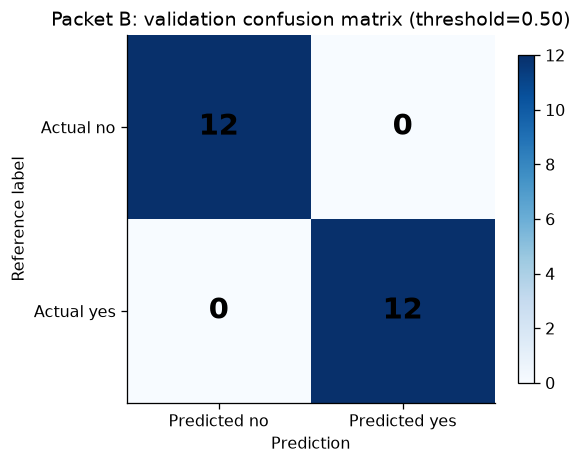

In [7]:
def metric_row(y_true, probability, threshold=0.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, prediction),
        "sensitivity_recall": recall_score(y_true, prediction, zero_division=0),
        "specificity": recall_score(y_true, prediction, pos_label=0, zero_division=0),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
        "brier": brier_score_loss(y_true, probability),
        "log_loss": log_loss(y_true, probability),
    }

baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
validation_probability_nb = model.predict_proba(X_validation)[:, 1]
validation_probability_baseline = baseline.predict_proba(X_validation)[:, 1]

validation_metrics = pd.DataFrame([
    {"model": "prior-only baseline", **metric_row(y_validation, validation_probability_baseline)},
    {"model": "Bernoulli naive Bayes", **metric_row(y_validation, validation_probability_nb)},
])
display(validation_metrics)
validation_metrics.to_csv(ASSET_DIR / "packet-b-validation-metrics.csv", index=False)

cm_validation = confusion_matrix(y_validation, validation_probability_nb >= 0.5)
fig, ax = plt.subplots(figsize=(5.3, 4.4))
image = ax.imshow(cm_validation, cmap="Blues", vmin=0)
for row in range(2):
    for col in range(2):
        ax.text(col, row, cm_validation[row, col], ha="center", va="center", fontsize=18, fontweight="bold")
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Predicted no", "Predicted yes"],
       yticklabels=["Actual no", "Actual yes"], xlabel="Prediction", ylabel="Reference label",
       title="Packet B: validation confusion matrix (threshold=0.50)")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(ASSET_DIR / "packet-b-validation-confusion-matrix.png", dpi=180, bbox_inches="tight")
plt.show()


### 从混淆矩阵到指标（示范作答）

$$
Sensitivity=\frac{TP}{TP+FN},\quad Specificity=\frac{TN}{TN+FP}
$$

$$
Precision=\frac{TP}{TP+FP},\quad Accuracy=\frac{TP+TN}{N}
$$

1. Validation 混淆矩阵：**TP=12、TN=12、FP=0、FN=0**。
2. Sensitivity $=12/(12+0)=1$；specificity $=12/(12+0)=1$。
3. Prior-only baseline 把所有人都判成阴性：specificity 因此等于 1，看着漂亮，可它把阳性全漏了，sensitivity=0，拿去筛查毫无意义。
4. Sensitivity 问的是“真实患者里找出了多少”；precision 问的是“判为阳性的人里有多少确实阳性”。

,threshold,accuracy,sensitivity_recall,specificity,precision,f1,roc_auc,pr_auc,brier,log_loss
0,0.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0118,0.0872


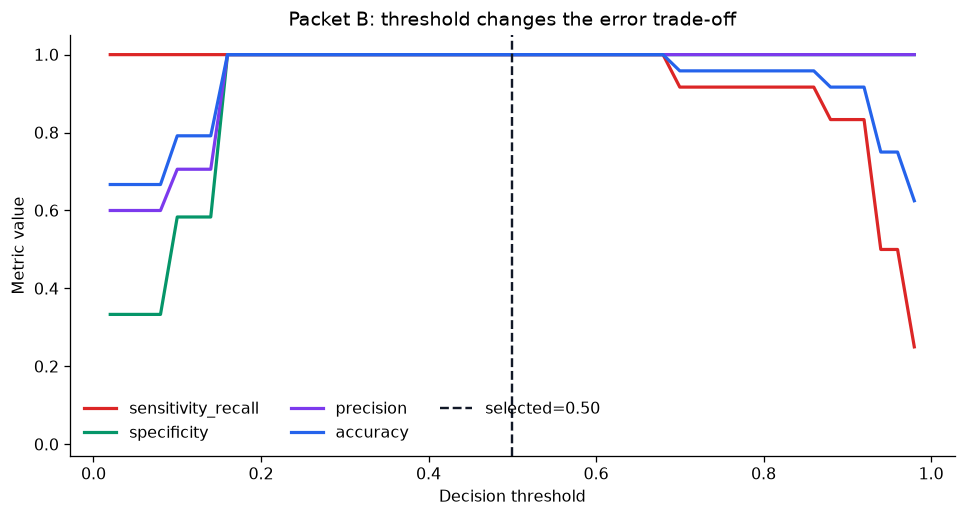

In [8]:
# 可修改交互 2：调整阈值，观察错误类型如何变化。
THRESHOLD = 0.50  # 尝试 0.10、0.25、0.50、0.75、0.90

threshold_grid = np.linspace(0.02, 0.98, 49)
threshold_results = pd.DataFrame([
    metric_row(y_validation, validation_probability_nb, threshold=t)
    for t in threshold_grid
])
selected_result = pd.DataFrame([
    metric_row(y_validation, validation_probability_nb, threshold=THRESHOLD)
])
display(selected_result)
threshold_results.to_csv(ASSET_DIR / "packet-b-threshold-path.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for metric, color in [("sensitivity_recall", "#dc2626"), ("specificity", "#059669"), ("precision", "#7c3aed"), ("accuracy", "#2563eb")]:
    ax.plot(threshold_results["threshold"], threshold_results[metric], label=metric, color=color, linewidth=2)
ax.axvline(THRESHOLD, color="#111827", linestyle="--", label=f"selected={THRESHOLD:.2f}")
ax.set(xlabel="Decision threshold", ylabel="Metric value", ylim=(-0.03, 1.05),
       title="Packet B: threshold changes the error trade-off")
ax.legend(ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / "packet-b-threshold-tradeoff.png", dpi=180, bbox_inches="tight")
plt.show()


### Packet B 审计四问（示范作答）

1. **可以得出什么？** 在当前这批 validation 样本上，NB 明显优于 prior-only baseline，而且在这个阈值下没有出现 FN 或 FP。
2. **还不能得出什么？** 不能就此说真实的 sensitivity 是 100%，也判断不了外部泛化和校准是否稳定。
3. **如何修订当前决定？** 保留 NB 作为简单基线；如果漏诊的代价更高，可以在 validation 上把阈值调低，但必须同时记下 specificity 和 precision 付出的代价。
4. **什么证据会改变决定？** Locked test、不确定区间、条件独立审计和外部数据。注意 test 一旦参与调整，就不再是独立的最终评价了。

### 指标主张 Evidence Card（示范核验）

**待审查主张：** “医学筛查应该优先看 sensitivity。”教材、官方指标定义、论文或 AI 都可以作为来源，但都要拿本数据的混淆矩阵独立核对一遍。

**核验结论：** 这句话只在漏诊代价明显更高的筛查场景下方向是对的；把 sensitivity 当成所有医学任务唯一该看的指标，属于过度概括。更稳妥的说法是：**事先规定好主要指标，并同时报告 sensitivity、specificity、precision、所用阈值、校准和不确定性。**

## Packet C｜“朴素”假设审计：相关证据会被重复计算吗？

条件独立说的不是特征在总体上互不相关。它要求的是：**在已经知道是不是患病之后，再多知道一个症状，也不会改变另一个症状出现的概率**。

真实的症状常常由同一套病理机制驱动，所以这个假设多半只是个近似。下面看看在这份数据里，它近似到什么程度。

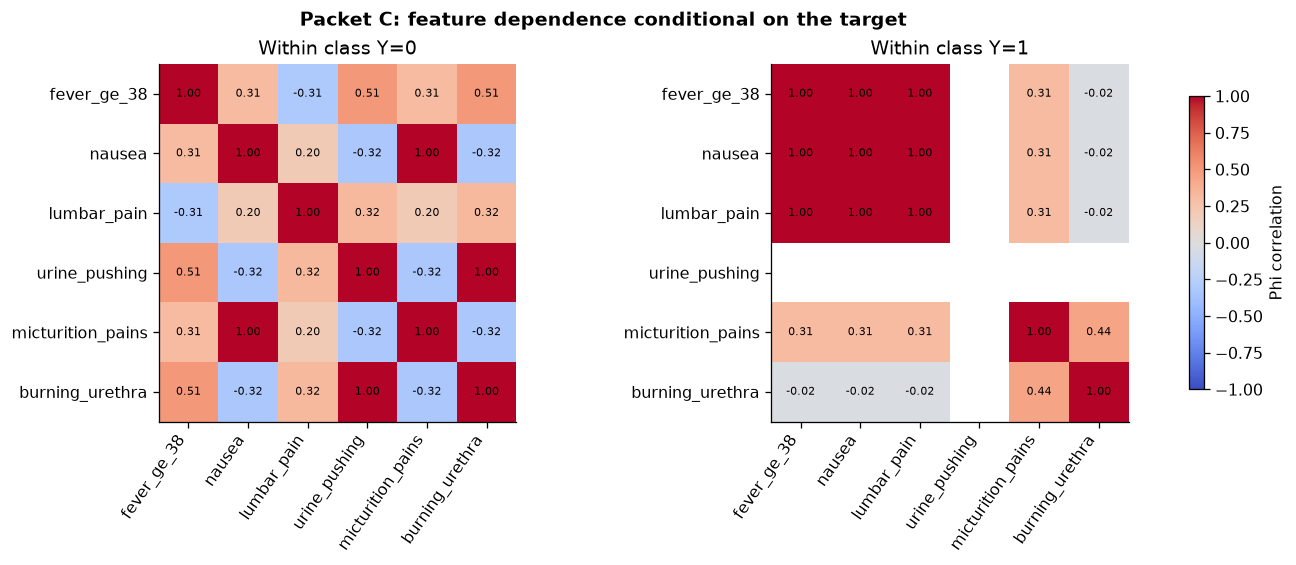

,target_status,feature_1,feature_2,phi_correlation,abs_phi
7,0,nausea,micturition_pains,1.0000,1.0000
20,1,nausea,lumbar_pain,1.0000,1.0000
13,0,urine_pushing,burning_urethra,1.0000,1.0000
16,1,fever_ge_38,lumbar_pain,1.0000,1.0000
15,1,fever_ge_38,nausea,1.0000,1.0000
4,0,fever_ge_38,burning_urethra,0.5061,0.5061
2,0,fever_ge_38,urine_pushing,0.5061,0.5061
29,1,micturition_pains,burning_urethra,0.4442,0.4442
9,0,lumbar_pain,urine_pushing,0.3208,0.3208
11,0,lumbar_pain,burning_urethra,0.3208,0.3208


In [9]:
dependence_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for axis, disease_status in zip(axes, [0, 1]):
    corr = X[y == disease_status].corr()
    shown = np.ma.masked_invalid(corr.to_numpy())
    image = axis.imshow(shown, cmap="coolwarm", vmin=-1, vmax=1)
    axis.set_xticks(range(len(FEATURES)), FEATURES, rotation=55, ha="right")
    axis.set_yticks(range(len(FEATURES)), FEATURES)
    axis.set_title(f"Within class Y={disease_status}")
    for row in range(len(FEATURES)):
        for col in range(len(FEATURES)):
            value = corr.iloc[row, col]
            if not np.isnan(value):
                axis.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7)
    for row in range(len(FEATURES)):
        for col in range(row + 1, len(FEATURES)):
            dependence_rows.append({
                "target_status": disease_status,
                "feature_1": FEATURES[row],
                "feature_2": FEATURES[col],
                "phi_correlation": corr.iloc[row, col],
            })
fig.colorbar(image, ax=axes, shrink=0.82, label="Phi correlation")
fig.suptitle("Packet C: feature dependence conditional on the target", fontweight="bold")
fig.savefig(ASSET_DIR / "packet-c-conditional-dependence.png", dpi=180, bbox_inches="tight")
plt.show()

dependence_table = pd.DataFrame(dependence_rows)
dependence_table.to_csv(ASSET_DIR / "packet-c-conditional-dependence.csv", index=False)
display(dependence_table.assign(abs_phi=lambda d: d["phi_correlation"].abs()).sort_values("abs_phi", ascending=False).head(10))


### 先解释，再下结论（示范作答）

- 类别内相关系数等于 1，说明两个症状在该类别里完全同步出现，它们提供的显然不是两份独立的证据。
- `NaN` 不是“没有相关”。它一般意味着某个特征在这个类别里根本不变、方差为 0，相关系数因此没有定义。
- 条件独立不成立，并不等于 NB 一定会分错——假设是错的，决策边界照样可能落在对的位置上。
- 但即使类别判对了，posterior 仍可能过度自信、校准很差；极端情况下，只是把同一个症状重复录了一遍，概率就跨过了阈值。

,fever_ge_38,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,original_probability,duplicate_probability,probability_change,decision_changed_at_0.5
54,0,1,1,0,1,1,0.3755,0.5966,0.2211,True
19,1,1,0,0,1,0,0.4078,0.6287,0.2210,True
47,1,1,1,1,0,1,0.3711,0.5920,0.2209,True
22,0,1,1,0,1,0,0.2622,0.4664,0.2042,False
14,0,1,1,1,0,0,0.5340,0.7381,0.2041,False
51,1,1,0,0,1,1,0.5381,0.7413,0.2032,False
15,1,1,1,1,0,0,0.2586,0.4617,0.2031,False
46,0,1,1,1,0,1,0.6597,0.8266,0.1669,False
34,0,1,0,0,0,1,0.1610,0.3207,0.1597,False
11,1,1,0,1,0,0,0.6895,0.8452,0.1558,False


Decisions changed: 5 / 64
Largest absolute probability shift: 0.221082487429704


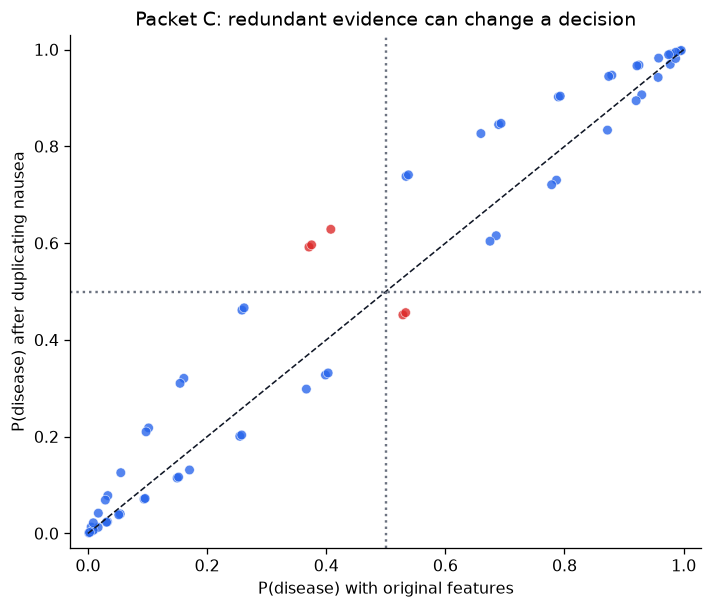

In [10]:
# 可修改交互 3：模拟同一症状被重复录入，观察 posterior 是否不合理地变化。
DUPLICATED_FEATURE = "nausea"

X_train_duplicate = X_train.copy()
X_train_duplicate[f"{DUPLICATED_FEATURE}_duplicate"] = X_train_duplicate[DUPLICATED_FEATURE]
duplicate_model = BernoulliNB(alpha=ALPHA).fit(X_train_duplicate, y_train)

all_profiles = pd.DataFrame(
    [[(profile >> bit) & 1 for bit in range(len(FEATURES))] for profile in range(2 ** len(FEATURES))],
    columns=FEATURES,
)
all_profiles_duplicate = all_profiles.copy()
all_profiles_duplicate[f"{DUPLICATED_FEATURE}_duplicate"] = all_profiles_duplicate[DUPLICATED_FEATURE]

duplicate_audit = all_profiles.copy()
duplicate_audit["original_probability"] = model.predict_proba(all_profiles)[:, 1]
duplicate_audit["duplicate_probability"] = duplicate_model.predict_proba(all_profiles_duplicate)[:, 1]
duplicate_audit["probability_change"] = duplicate_audit["duplicate_probability"] - duplicate_audit["original_probability"]
duplicate_audit["decision_changed_at_0.5"] = (
    (duplicate_audit["original_probability"] >= 0.5)
    != (duplicate_audit["duplicate_probability"] >= 0.5)
)
duplicate_audit.to_csv(ASSET_DIR / "packet-c-duplicate-feature-audit.csv", index=False)

display(duplicate_audit.reindex(duplicate_audit["probability_change"].abs().sort_values(ascending=False).index).head(10))
print("Decisions changed:", int(duplicate_audit["decision_changed_at_0.5"].sum()), "/", len(duplicate_audit))
print("Largest absolute probability shift:", duplicate_audit["probability_change"].abs().max())

fig, ax = plt.subplots(figsize=(6.3, 5.4))
colors = np.where(duplicate_audit["decision_changed_at_0.5"], "#dc2626", "#2563eb")
ax.scatter(duplicate_audit["original_probability"], duplicate_audit["duplicate_probability"],
           c=colors, alpha=0.78, edgecolor="white", linewidth=0.4)
ax.plot([0,1], [0,1], "--", color="#111827", linewidth=1)
ax.axvline(0.5, color="#6b7280", linestyle=":")
ax.axhline(0.5, color="#6b7280", linestyle=":")
ax.set(xlim=(-0.03,1.03), ylim=(-0.03,1.03),
       xlabel="P(disease) with original features",
       ylabel=f"P(disease) after duplicating {DUPLICATED_FEATURE}",
       title="Packet C: redundant evidence can change a decision")
fig.tight_layout()
fig.savefig(ASSET_DIR / "packet-c-duplicate-feature-shift.png", dpi=180, bbox_inches="tight")
plt.show()


,model,accuracy,brier,log_loss
0,original,1.0,0.0118,0.0872
1,duplicate nausea,1.0,0.0149,0.0901


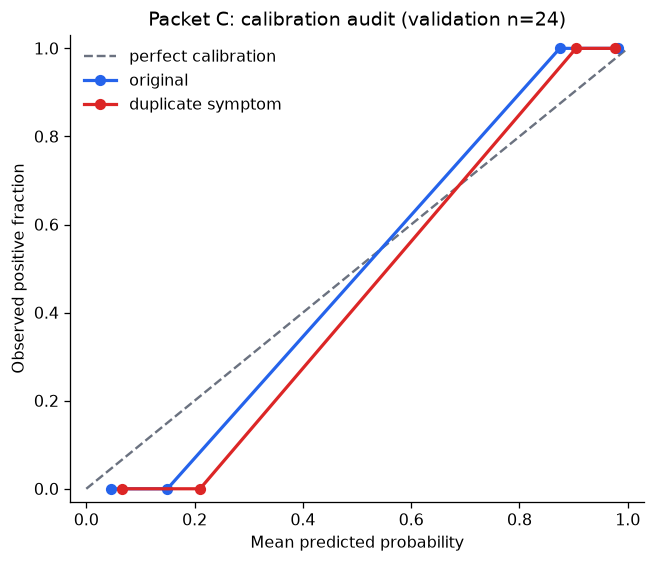

Caution: with only 24 validation samples, this curve is diagnostic evidence, not a stable calibration claim.


In [11]:
validation_duplicate = X_validation.copy()
validation_duplicate[f"{DUPLICATED_FEATURE}_duplicate"] = validation_duplicate[DUPLICATED_FEATURE]
validation_probability_duplicate = duplicate_model.predict_proba(validation_duplicate)[:, 1]

probability_quality = pd.DataFrame([
    {
        "model": "original",
        "accuracy": accuracy_score(y_validation, validation_probability_nb >= 0.5),
        "brier": brier_score_loss(y_validation, validation_probability_nb),
        "log_loss": log_loss(y_validation, validation_probability_nb),
    },
    {
        "model": f"duplicate {DUPLICATED_FEATURE}",
        "accuracy": accuracy_score(y_validation, validation_probability_duplicate >= 0.5),
        "brier": brier_score_loss(y_validation, validation_probability_duplicate),
        "log_loss": log_loss(y_validation, validation_probability_duplicate),
    },
])
display(probability_quality)

fig, ax = plt.subplots(figsize=(5.8, 5.0))
ax.plot([0,1], [0,1], "--", color="#6b7280", label="perfect calibration")
for label, probability, color in [
    ("original", validation_probability_nb, "#2563eb"),
    ("duplicate symptom", validation_probability_duplicate, "#dc2626"),
]:
    observed, predicted = calibration_curve(y_validation, probability, n_bins=4, strategy="quantile")
    ax.plot(predicted, observed, marker="o", linewidth=2, color=color, label=label)
ax.set(xlabel="Mean predicted probability", ylabel="Observed positive fraction",
       xlim=(-0.03,1.03), ylim=(-0.03,1.03),
       title="Packet C: calibration audit (validation n=24)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / "packet-c-calibration-audit.png", dpi=180, bbox_inches="tight")
plt.show()
print("Caution: with only 24 validation samples, this curve is diagnostic evidence, not a stable calibration claim.")


### 概念辨析

| 概念 | 回答的问题 | 本例风险 |
|---|---|---|
| Accuracy | 当前阈值下总体分对了多少？ | 受类别比例和错误代价影响 |
| Sensitivity/Recall | 真阳性里找出了多少？ | 不说明阳性预测中有多少是真的 |
| Precision | 阳性预测里有多少是真的？ | 随患病率变化 |
| ROC-AUC | 随机一个阳性排在随机一个阴性前面的能力 | 不代表阈值选对了，也不代表校准好 |
| PR-AUC | 阳性类别上的 precision–recall 权衡 | 基线本身取决于阳性率 |
| Calibration | 预测 0.8 的那批样本真有约 80% 阳性吗？ | 小样本上曲线非常不稳 |
| Log loss/Brier | 预测概率离真实标签有多远？ | 极端而错误的概率会被重罚 |

### Packet C 决策矩阵（示范作答）

| 可选行动 | 理由/假设 | 期待证据 | 验证方式 | 停止条件或副作用 |
|---|---|---|---|---|
| 保留全部特征 | 模型简单，分类能力可能已经够用 | 指标和概率在新数据上依然稳定 | 外部测试、校准和误差分析 | 一旦发现结果依赖单一症状或概率失真就停 |
| 删掉重复或高度相关的症状 | 避免把同一份证据算两遍 | posterior 更稳，性能没有明显下降 | 特征消融加重复验证 | 有可能连真正有用的信号一起删掉 |
| 保留模型，但不解释原始 posterior | 分类也许可用，但概率的含义存疑 | 阈值决策足够稳定 | 比较 Brier/log loss 与校准曲线 | 需要绝对风险数值的场合不能这么用 |
| 先收集外部数据再决定 | 内部的规则化数据不足以支撑应用 | 外部指标、区间和校准都可接受 | 预注册的前瞻性外部验证 | 成本高，但临床试点前绕不开 |

### Packet C 审计四问（示范作答）

1. **可以得出什么？** 如果类别内的症状本就相关，或者被重复录入，NB 的 posterior 乃至阈值决策都可能改变。
2. **还不能得出什么？** 不能仅凭条件独立不成立，就断言 NB 分类一定失败；也不能拿 24 个 validation 样本证明校准稳定。
3. **如何修订当前决定？** 可以继续把 NB 当分类基线，但不要把原始 posterior 直接当成可靠的个体风险。
4. **什么证据会改变决定？** 去重/消融后的重复验证、更多用于校准的样本，以及独立的外部数据。

> ### CHECKPOINT 3（示范作答）
> 支持“表现好”的证据是：validation 上所有样本都分类正确，而且阈值在 0.25–0.50 之间移动时结果不变。但要说“可信”，还差真实的外部队列、站得住的校准、对条件依赖的处理，以及窄得多的不确定区间。

## Packet D｜课堂核心：锁定测试与统计不确定性

正式上课时，这个 Packet 要等模型、特征和阈值全部冻结之后才释放。课堂上只做三件事：locked test、混淆矩阵和 Wilson 区间；后面的测量误差压力测试留作课后挑战题。审阅版默认解锁。

In [12]:
# 正式学生分阶段版本应保持 False，教师到 Packet D 再改为 True。
UNLOCK_PACKET_D = False
PACKET_D_AVAILABLE = REVIEW_MODE or UNLOCK_PACKET_D
print("Packet D available:", PACKET_D_AVAILABLE)


Packet D available: True


,threshold,accuracy,sensitivity_recall,specificity,precision,f1,roc_auc,pr_auc,brier,log_loss
0,0.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0126,0.0745


,metric,estimate,ci_low,ci_high,denominator
0,accuracy,1.0,0.8620,1.0,24
1,sensitivity,1.0,0.7575,1.0,12
2,specificity,1.0,0.7575,1.0,12


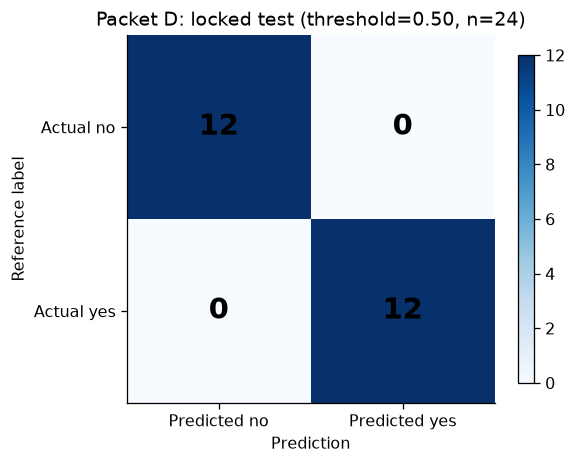

In [13]:
def wilson_interval(successes, total, z=1.959963984540054):
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return center - half, center + half

if not PACKET_D_AVAILABLE:
    display(Markdown("🔒 **Packet D 尚未释放。请先完成 CHECKPOINT 3。**"))
else:
    test_probability = model.predict_proba(X_test)[:, 1]
    test_prediction = (test_probability >= THRESHOLD).astype(int)
    test_metrics = pd.DataFrame([metric_row(y_test, test_probability, THRESHOLD)])
    display(test_metrics)
    test_metrics.to_csv(ASSET_DIR / "packet-d-locked-test-metrics.csv", index=False)

    cm_test = confusion_matrix(y_test, test_prediction)
    tn, fp, fn, tp = cm_test.ravel()
    interval_rows = []
    for name, successes, total in [
        ("accuracy", tp + tn, len(y_test)),
        ("sensitivity", tp, tp + fn),
        ("specificity", tn, tn + fp),
    ]:
        low, high = wilson_interval(successes, total)
        interval_rows.append({"metric": name, "estimate": successes/total, "ci_low": low, "ci_high": high, "denominator": total})
    interval_table = pd.DataFrame(interval_rows)
    display(interval_table)
    interval_table.to_csv(ASSET_DIR / "packet-d-wilson-ci.csv", index=False)

    fig, ax = plt.subplots(figsize=(5.3, 4.4))
    image = ax.imshow(cm_test, cmap="Blues", vmin=0)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, cm_test[row, col], ha="center", va="center", fontsize=18, fontweight="bold")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Predicted no", "Predicted yes"],
           yticklabels=["Actual no", "Actual yes"], xlabel="Prediction", ylabel="Reference label",
           title=f"Packet D: locked test (threshold={THRESHOLD:.2f}, n={len(y_test)})")
    fig.colorbar(image, ax=ax, shrink=0.8)
    fig.tight_layout()
    fig.savefig(ASSET_DIR / "packet-d-locked-test-confusion-matrix.png", dpi=180, bbox_inches="tight")
    plt.show()


metric,accuracy,sensitivity,specificity
flip_rate,,,
0.00,1.0000,1.0000,1.0000
0.02,0.9838,0.9775,0.9902
0.05,0.9554,0.9470,0.9638
0.10,0.9111,0.8968,0.9253
0.15,0.8628,0.8423,0.8833
0.20,0.8117,0.7895,0.8338


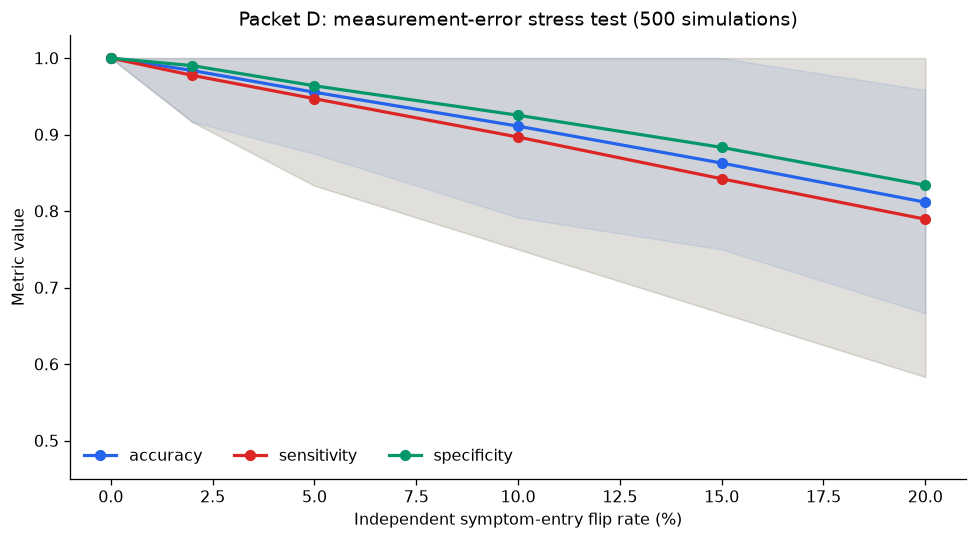

This is a transparent synthetic stress test, not external clinical validation.


In [14]:
# 课后挑战题（可修改交互 4）：症状测量/录入错误压力测试。
FLIP_RATES = [0.00, 0.02, 0.05, 0.10, 0.15, 0.20]
N_SIMULATIONS = 500
STRESS_THRESHOLD = THRESHOLD

if not PACKET_D_AVAILABLE:
    display(Markdown("🔒 **Packet D 尚未释放。**"))
else:
    rng = np.random.default_rng(20260903)
    x_base = X_test.to_numpy(dtype=bool)
    y_base = y_test.to_numpy(dtype=bool)
    stress_rows = []
    for flip_rate in FLIP_RATES:
        masks = rng.random((N_SIMULATIONS, *x_base.shape)) < flip_rate
        stressed = np.logical_xor(x_base[None, :, :], masks).astype(int)
        flat = pd.DataFrame(stressed.reshape(-1, len(FEATURES)), columns=FEATURES)
        probability = model.predict_proba(flat)[:, 1].reshape(N_SIMULATIONS, len(y_base))
        prediction = probability >= STRESS_THRESHOLD
        truth = y_base[None, :]
        tp_sim = (prediction & truth).sum(axis=1)
        tn_sim = ((~prediction) & (~truth)).sum(axis=1)
        fp_sim = (prediction & (~truth)).sum(axis=1)
        fn_sim = ((~prediction) & truth).sum(axis=1)
        values = {
            "accuracy": (tp_sim + tn_sim) / len(y_base),
            "sensitivity": tp_sim / (tp_sim + fn_sim),
            "specificity": tn_sim / (tn_sim + fp_sim),
        }
        for metric_name, metric_values in values.items():
            stress_rows.append({
                "flip_rate": flip_rate,
                "metric": metric_name,
                "mean": metric_values.mean(),
                "q025": np.quantile(metric_values, 0.025),
                "q975": np.quantile(metric_values, 0.975),
            })
    stress_table = pd.DataFrame(stress_rows)
    display(stress_table.pivot(index="flip_rate", columns="metric", values="mean"))
    stress_table.to_csv(ASSET_DIR / "packet-d-measurement-error-stress.csv", index=False)

    fig, ax = plt.subplots(figsize=(8.6, 4.8))
    colors = {"accuracy": "#2563eb", "sensitivity": "#dc2626", "specificity": "#059669"}
    for metric_name, color in colors.items():
        subset = stress_table[stress_table["metric"] == metric_name]
        x_percent = subset["flip_rate"].to_numpy() * 100
        ax.plot(x_percent, subset["mean"], marker="o", linewidth=2, color=color, label=metric_name)
        ax.fill_between(x_percent, subset["q025"], subset["q975"], color=color, alpha=0.10)
    ax.set(xlabel="Independent symptom-entry flip rate (%)", ylabel="Metric value",
           ylim=(0.45, 1.03), title=f"Packet D: measurement-error stress test ({N_SIMULATIONS} simulations)")
    ax.legend(frameon=False, ncol=3)
    fig.tight_layout()
    fig.savefig(ASSET_DIR / "packet-d-measurement-error-stress.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("This is a transparent synthetic stress test, not external clinical validation.")


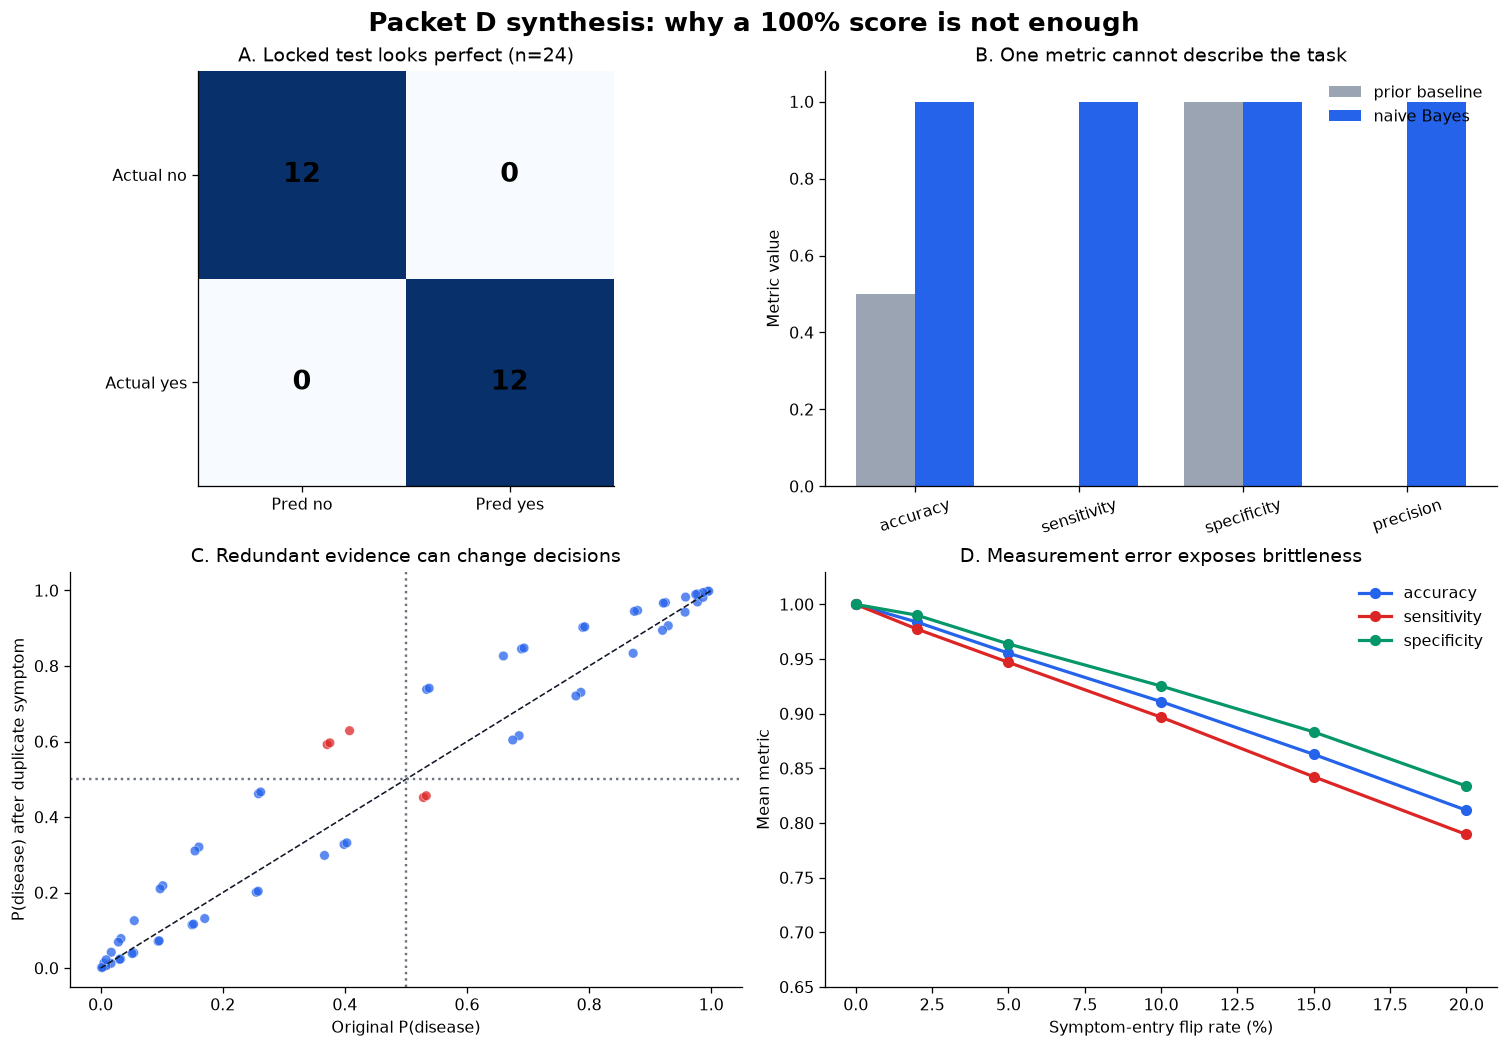

In [15]:
if PACKET_D_AVAILABLE:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

    # A: locked test confusion matrix
    axis = axes[0, 0]
    image = axis.imshow(cm_test, cmap="Blues", vmin=0)
    for row in range(2):
        for col in range(2):
            axis.text(col, row, cm_test[row, col], ha="center", va="center", fontsize=17, fontweight="bold")
    axis.set(xticks=[0,1], yticks=[0,1], xticklabels=["Pred no", "Pred yes"],
             yticklabels=["Actual no", "Actual yes"], title="A. Locked test looks perfect (n=24)")

    # B: baseline versus NB
    axis = axes[0, 1]
    names = ["accuracy", "sensitivity_recall", "specificity", "precision"]
    positions = np.arange(len(names)); width = 0.36
    baseline_values = [validation_metrics.iloc[0][name] for name in names]
    nb_values = [validation_metrics.iloc[1][name] for name in names]
    axis.bar(positions-width/2, baseline_values, width, color="#9aa4b2", label="prior baseline")
    axis.bar(positions+width/2, nb_values, width, color="#2563eb", label="naive Bayes")
    axis.set_xticks(positions, [name.replace("_recall", "") for name in names], rotation=18)
    axis.set_ylim(0, 1.08); axis.set_ylabel("Metric value"); axis.legend(frameon=False)
    axis.set_title("B. One metric cannot describe the task")

    # C: duplicate-feature shift
    axis = axes[1, 0]
    colors = np.where(duplicate_audit["decision_changed_at_0.5"], "#dc2626", "#2563eb")
    axis.scatter(duplicate_audit["original_probability"], duplicate_audit["duplicate_probability"],
                 c=colors, alpha=0.75, edgecolor="white", linewidth=0.3)
    axis.plot([0,1], [0,1], "--", color="#111827", linewidth=1)
    axis.axvline(0.5, color="#6b7280", linestyle=":"); axis.axhline(0.5, color="#6b7280", linestyle=":")
    axis.set(xlabel="Original P(disease)", ylabel="P(disease) after duplicate symptom",
             title="C. Redundant evidence can change decisions")

    # D: stress path
    axis = axes[1, 1]
    for metric_name, color in {"accuracy":"#2563eb", "sensitivity":"#dc2626", "specificity":"#059669"}.items():
        subset = stress_table[stress_table["metric"] == metric_name]
        axis.plot(subset["flip_rate"]*100, subset["mean"], marker="o", linewidth=2, color=color, label=metric_name)
    axis.set(xlabel="Symptom-entry flip rate (%)", ylabel="Mean metric", ylim=(0.65,1.03),
             title="D. Measurement error exposes brittleness")
    axis.legend(frameon=False)

    fig.suptitle("Packet D synthesis: why a 100% score is not enough", fontsize=16, fontweight="bold")
    fig.savefig(ASSET_DIR / "main-result-clean-vs-audit.png", dpi=180, bbox_inches="tight")
    plt.show()


### Packet D 审计四问（示范作答）

1. **可以得出什么？** 冻结后的方案在 24 个内部 test 样本上 24/24 全对，说明它确实把这套规则化数据里的模式复现出来了。
2. **还不能得出什么？** 不能由此断言总体 sensitivity=100%，更谈不上真实患者的代表性、跨中心泛化或临床效用。
3. **如何修订当前决定？** 95% Wilson 区间的下限并不好看：accuracy 约 0.862，sensitivity 和 specificity 约 0.758。所以只批准教学/方法研究和独立验证，不批准临床试点。
4. **什么证据会改变决定？** 预注册的真实多中心前瞻性队列、可靠的标签、固定的阈值，以及完整的校准与错误代价报告。

**挑战题结论：** 模拟症状录入错误之后性能会往下走，说明模型没有看上去那么稳。但这只是一个透明的合成测试，既替代不了外部验证，也估不出真实世界的错误率。还有一点值得注意：条件独立只是近似，NB 在这种规则化数据上照样可能全部分对，真正受影响的是 posterior 的数值和校准。

**别忘了患病率：** $PPV=\frac{Sensitivity\times Prevalence}{Sensitivity\times Prevalence+(1-Specificity)(1-Prevalence)}$。同样的 sensitivity 和 specificity，患病率一低，阳性预测里就会挤进大量假阳性，precision 随之下滑。

### 当前决定（示范作答）

- [ ] 批准进入临床试点
- [ ] 仅批准继续教学/方法研究
- [x] 要求真实外部队列和预先注册的评价方案
- [ ] 拒绝继续使用朴素贝叶斯

**依据：** 内部测试 24/24 很好看，但样本太少、区间太宽；数据本身是专家按规则构造的；条件依赖和模拟的录入误差又都动摇了概率的可信度。作为教学或研究基线它没问题，但凭这些还进不了临床试点。

# 课后迁移作业｜近迁移 + 新情境迁移

> **课堂导航：** 课上做完 Packet D 之后，请跳过本节和下一个代码单元，直接翻到后面的“Section 2 收束记录”。这一节课后再做。

把目标换成 `nephritis`（肾盂肾炎），完成以下任务：

1. 在不动 locked test 的前提下重新训练模型。
2. 报告 validation 的 confusion matrix、sensitivity、specificity、precision 和 F1。
3. 权衡漏诊与误报的代价，选定一个阈值，并说明依据。
4. 找出至少一组违反条件独立的特征。
5. 回答：**为什么医学诊断模型不能只看 accuracy？**

下面是已经填好的教师示范代码。

### 新情境迁移：低患病率筛查（示范作答）

假设有一项遗传病筛查，目标人群的患病率只有 1%，模型的 sensitivity 和 specificity 都是 95%。两个指标看着都很高，但：

$$
Precision=\frac{0.95\times0.01}{0.95\times0.01+0.05\times0.99}\approx0.161
$$

也就是说，被判为阳性的人里只有约 **16.1%** 真的患病，剩下八成多都是假阳性。precision 是跟着患病率走的——这也正是只报一个 accuracy 远远不够的原因。

In [16]:
# 迁移任务示范：使用同样流程预测 nephritis，不覆盖主分析。
TRANSFER_TARGET = "nephritis"
y_transfer = data[TRANSFER_TARGET].copy()

Xt_train_validation, Xt_test, yt_train_validation, yt_test = train_test_split(
    X, y_transfer, test_size=0.20, random_state=RANDOM_STATE, stratify=y_transfer
)
Xt_train, Xt_validation, yt_train, yt_validation = train_test_split(
    Xt_train_validation,
    yt_train_validation,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=yt_train_validation,
)

transfer_model = BernoulliNB(alpha=ALPHA).fit(Xt_train, yt_train)
transfer_validation_probability = transfer_model.predict_proba(Xt_validation)[:, 1]

transfer_thresholds = pd.DataFrame([
    metric_row(yt_validation, transfer_validation_probability, threshold=t)
    for t in [0.10, 0.25, 0.50, 0.75, 0.90]
])
display(transfer_thresholds)

# Validation 在 0.50 阈值已无错误，因此保留预设阈值，不根据 test 调参。
TRANSFER_THRESHOLD = 0.50
transfer_test_probability = transfer_model.predict_proba(Xt_test)[:, 1]
transfer_test_metrics = pd.DataFrame([
    metric_row(yt_test, transfer_test_probability, threshold=TRANSFER_THRESHOLD)
])
display(transfer_test_metrics)
display(pd.DataFrame(
    confusion_matrix(yt_test, transfer_test_probability >= TRANSFER_THRESHOLD),
    index=["actual no", "actual yes"],
    columns=["predicted no", "predicted yes"],
))

transfer_thresholds.to_csv(ASSET_DIR / "transfer-nephritis-validation-thresholds.csv", index=False)
transfer_test_metrics.to_csv(ASSET_DIR / "transfer-nephritis-locked-test-metrics.csv", index=False)

print(f"Transfer target positive rate: {y_transfer.mean():.3f}")
print("Boundary: this is still the same small expert-rule dataset; perfect internal metrics do not establish clinical utility.")


,threshold,accuracy,sensitivity_recall,specificity,precision,f1,roc_auc,pr_auc,brier,log_loss
0,0.10,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0002,0.0085
1,0.25,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0002,0.0085
2,0.50,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0002,0.0085
3,0.75,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0002,0.0085
4,0.90,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0002,0.0085


,threshold,accuracy,sensitivity_recall,specificity,precision,f1,roc_auc,pr_auc,brier,log_loss
0,0.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0003,0.0129


,predicted no,predicted yes
actual no,14,0
actual yes,0,10


Transfer target positive rate: 0.417
Boundary: this is still the same small expert-rule dataset; perfect internal metrics do not establish clinical utility.


# CERB 模型审计 Memo（示范作答）

## Claim

不批准该模型进入临床试点。可以保留为教学或方法研究的基线，等预注册的真实外部验证做完之后再重新评估。

## Evidence

1. **分类证据：** 锁定测试 24/24 全对，但一共只有 12 个阳性和 12 个阴性。
2. **概率/假设证据：** 把“恶心”重复录一遍，64 种可能的症状组合里有 5 种越过了 0.5 阈值，最大概率变化约 0.221。
3. **不确定性/稳健性证据：** sensitivity 和 specificity 的 Wilson 下限约 0.758；症状有 10% 被翻转时，平均 sensitivity 降到约 0.897。

## Reasoning

内部准确率高，更可能说明模型把这套规则化数据的模式学下来了，而不是证明它在真实临床里同样成立。筛查场景尤其要盯住漏诊，小样本上的“零错误”替代不了外部 sensitivity、校准和错误代价的评估。

## Boundary

这份数据只有 120 条专家构造的样本，既没有医院和人口学信息，也没有真实的诊断过程、缺失和测量噪声。下一步应该换成独立的多中心前瞻性数据，并事先把标签定义、阈值、主要指标、缺失处理和亚组分析都规定好。

# Section 2 收束记录｜证据综合与观点修订

> Section 2 的时间表在 Packet B 之前已经给过；这里集中记录最后 7 分钟的 re-vote、CERB 和 exit ticket。

### Re-vote（示范作答）

初始选择：**只支持教学/方法基线并补充证据**；最终选择：**要求真实外部验证**；置信度：**85% → 95%**。
真正让我改主意的不是某一条证据，而是几件事叠在一起：数据是按专家规则造的、测试集小到区间很宽、重复一个特征就能改变判断、加一点录入噪声性能就往下掉。

### Peer challenge（示范作答）

- **最强反对意见：** 模型简单、可解释，内部测试还完全正确，低成本试点也许值得一试。
- **回应：** 这批样本共用同一套构造规则，24 例撑不起对临床风险的判断。让真实患者参与之前，先把独立的、预注册的外部研究做完。
- **仍然回答不了的：** 真实人群中的症状误报率、标签误差、患病率，以及跨医院的分布变化各有多大。

### Exit ticket（示范作答）

1. **“朴素”朴素在哪？** 在给定类别之后，把各个特征近似当作条件独立。
2. **数据划分最容易被用错的地方？** 拿 validation/test 反复调参，或者在划分之前就用全量数据做了特征处理。
3. **为什么 discrimination 和 calibration 不能互相替代？** 前者评价的是排序，后者评价的是概率数值本身可不可信；排序全对，也不保证 0.8 真的代表约 80%。
4. **迁移到基因表达分类时先检查什么？** 先按患者而不是按样本划分数据，标准化和特征选择一律只在训练集内部做，然后重点盯高维小样本、批次效应和各种泄漏路径。

# 工作词汇表

| English | 本课工作含义 |
|---|---|
| sample / observation unit | 一行观测对象；本数据中是一条专家构造的症状—标签组合，不是真实患者记录 |
| feature | 用于预测的输入变量 |
| label/target | 希望预测的已知结果 |
| model | 用参数表示输入与输出关系的数学函数 |
| training | 从训练数据估计模型参数 |
| prediction | 用已经固定下来的模型对新输入产生输出 |
| validation | 选择方案和阈值、发现问题 |
| locked test | 方案冻结后用于最终评价的数据 |
| generalization | 在没有参与建模的新样本上保持表现 |
| loss | 衡量单次预测与真实标签差距的函数 |
| cross-entropy / log loss | 常用于评价分类概率；错得越自信，罚得越重 |
| mean squared error | 回归中常用的平方误差损失 |
| sensitivity / recall | 真阳性中被模型找出的比例 |
| specificity | 真阴性中被模型排除的比例 |
| precision | 阳性预测中真正为阳性的比例 |
| ROC-AUC / PR-AUC | 跨阈值评价排序能力；PR-AUC 更聚焦阳性类别 |
| prior | 还没看到当前特征时的类别概率 |
| likelihood | 给定类别时，看到这些特征取值的概率项 |
| posterior | 看过特征之后的类别概率 |
| conditional independence | 给定类别后，模型把各特征当作互不影响 |
| calibration | 预测概率与实际发生频率之间的吻合程度 |

## 数据来源

UCI Machine Learning Repository, **Acute Inflammations**, DOI: 10.24432/C5V59S，许可：CC BY 4.0。原始数据是医学专家为测试泌尿系统疾病专家系统而构造的，并非真实临床队列。

In [17]:
import sklearn

session_info = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "review_mode": REVIEW_MODE,
    "random_state": RANDOM_STATE,
    "dataset_exists": DATA_PATH.exists(),
    "generated_assets": sorted(path.name for path in ASSET_DIR.glob("packet-*")),
}
display(session_info)
print("Notebook execution complete. Interpretive answers remain for the student/reviewer.")


{'python': '3.14.6',
 'numpy': '2.4.6',
 'pandas': '3.0.3',
 'scikit_learn': '1.9.0',
 'review_mode': True,
 'random_state': 7,
 'dataset_exists': True,
 'generated_assets': ['packet-b-threshold-path.csv',
  'packet-b-threshold-tradeoff.png',
  'packet-b-validation-confusion-matrix.png',
  'packet-b-validation-metrics.csv',
  'packet-c-calibration-audit.png',
  'packet-c-conditional-dependence.csv',
  'packet-c-conditional-dependence.png',
  'packet-c-duplicate-feature-audit.csv',
  'packet-c-duplicate-feature-shift.png',
  'packet-d-locked-test-confusion-matrix.png',
  'packet-d-locked-test-metrics.csv',
  'packet-d-measurement-error-stress.csv',
  'packet-d-measurement-error-stress.png',
  'packet-d-wilson-ci.csv']}

Notebook execution complete. Interpretive answers remain for the student/reviewer.
